# Problem ID: Category01_Problem01 — Autonomous Grid-World Navigation with Obstacle Avoidance

### 1. Problem Scenario:
A delivery agent operates in a **4×4 warehouse grid**. The agent starts at **(0, 0)** and must find an efficient route to the charging station at **(3, 3)**.

A hazardous spill is located at **(1, 1)**, and a static storage shelf blocks cell **(2, 2)**. The agent must learn a route that reaches the charging station while avoiding the hazardous cell and the blocked shelf location.

### 2. System Specifications:
- **State Space ($S$):** 16 discrete coordinate cells indexed from 0 to 15, where $s = \text{row} \times 4 + \text{col}$.
- **Action Space ($A$):** 4 discrete movements: `0: UP`, `1: DOWN`, `2: LEFT`, `3: RIGHT`.
- **Reward Function:** Goal = `+10.0`, Trap/Hazard = `-10.0`, Step Penalty = `-1.0`.
- **Collision Rule:** Moving into the obstacle at (2, 2) or outside the grid leaves the agent in its current cell and gives a `-1.0` step penalty.
- **Episode Termination:** The episode ends when the agent reaches the goal or enters the hazardous cell, or when the maximum step limit is reached.

### 3. Student Implementation Deliverables:
1. **Task 1 (Cell 4):** Implement the $\epsilon$-Greedy action selection policy.
2. **Task 2 (Cell 5):** Implement the Tabular Q-Learning Bellman update rule:
   $$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$
   For a terminal transition, use `target = reward`.
3. **Execute & Verify (Cells 6 & 7):** Run the simulation driver and inspect the reward convergence and step-count trajectory.


In [1]:
# Cell 2: Standard Libraries & Environment Parameters (LOCKED)
import numpy as np
import matplotlib.pyplot as plt
import random

# Set deterministic seed for reproducible results
np.random.seed(42)
random.seed(42)

# Environment Spatial Bounds
GRID_SIZE = (4, 4)
START_STATE = (0, 0)
GOAL_STATE = (3, 3)
TRAP_STATE = (1, 1)
OBSTACLE_STATE = (2, 2)

# Reinforcement Learning & Simulation Parameters
NUM_EPISODES = 300
MAX_STEPS_PER_EPISODE = 50
ALPHA = 0.1       # Learning Rate
GAMMA = 0.9       # Discount Factor
EPSILON = 0.2     # Exploration Rate


In [2]:
# Cell 3: Environment Simulator Scaffold (LOCKED)
class GridWorldEnv:
    def __init__(self, size=GRID_SIZE):
        self.rows, self.cols = size
        self.reset()

    def reset(self):
        """Resets agent to start position and returns discrete state index."""
        self.agent_pos = list(START_STATE)
        return self._get_state_idx(self.agent_pos)

    def _get_state_idx(self, pos):
        return pos[0] * self.cols + pos[1]

    def step(self, action):
        """
        Executes action: 0: UP, 1: DOWN, 2: LEFT, 3: RIGHT
        Returns: (next_state, reward, done)
        """
        action_deltas = {
            0: (-1, 0),
            1: (1, 0),
            2: (0, -1),
            3: (0, 1)
        }

        dr, dc = action_deltas.get(action, (0, 0))

        # Calculate tentative position while keeping the agent inside the grid
        new_r = min(max(self.agent_pos[0] + dr, 0), self.rows - 1)
        new_c = min(max(self.agent_pos[1] + dc, 0), self.cols - 1)

        # Check obstacle collision
        if (new_r, new_c) == OBSTACLE_STATE:
            new_r, new_c = self.agent_pos[0], self.agent_pos[1]

        self.agent_pos = [new_r, new_c]
        current_pos = tuple(self.agent_pos)
        next_state = self._get_state_idx(self.agent_pos)

        if current_pos == GOAL_STATE:
            return next_state, 10.0, True
        elif current_pos == TRAP_STATE:
            return next_state, -10.0, True
        else:
            return next_state, -1.0, False


In [3]:
# Cell 4: [TASK 1] Agent Class & Action Selection (SOLUTION)
class QLearningAgent:
    def __init__(self, num_states, num_actions, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON):
        self.num_states = num_states
        self.num_actions = num_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.q_table = np.zeros((num_states, num_actions))

    def choose_action(self, state):
        # Explore with probability epsilon
        if random.random() < self.epsilon:
            return random.randint(0, self.num_actions - 1)

        # Exploit the action having the highest Q-value
        return int(np.argmax(self.q_table[state]))


In [4]:
# Cell 5: [TASK 2] Q-Learning Bellman Update (SOLUTION)
def update_agent(self, state, action, reward, next_state, done):
    # Current Q-value for the selected state-action pair
    current_q = self.q_table[state, action]

    # Do not bootstrap from the next state when the transition is terminal
    if done:
        target = reward
    else:
        target = reward + self.gamma * np.max(self.q_table[next_state])

    # Bellman Q-learning update
    self.q_table[state, action] = current_q + self.alpha * (target - current_q)

QLearningAgent.update_agent = update_agent


In [5]:
# Cell 6: Simulation Execution & Test Driver (LOCKED)
env = GridWorldEnv()
agent = QLearningAgent(num_states=16, num_actions=4)

rewards_history = []
steps_history = []

for ep in range(NUM_EPISODES):
    state = env.reset()
    total_reward = 0
    step_count = 0
    done = False

    while not done and step_count < MAX_STEPS_PER_EPISODE:
        action = agent.choose_action(state)
        next_state, reward, done = env.step(action)
        agent.update_agent(state, action, reward, next_state, done)

        state = next_state
        total_reward += reward
        step_count += 1

    rewards_history.append(total_reward)
    steps_history.append(step_count)

print(f"Simulation completed across {NUM_EPISODES} episodes.")
print(f"Average Reward (Last 20 Episodes): {np.mean(rewards_history[-20:]):.2f}")
print(f"Average Steps to Goal (Last 20 Episodes): {np.mean(steps_history[-20:]):.2f}")


Simulation completed across 300 episodes.
Average Reward (Last 20 Episodes): 1.45
Average Steps to Goal (Last 20 Episodes): 7.55


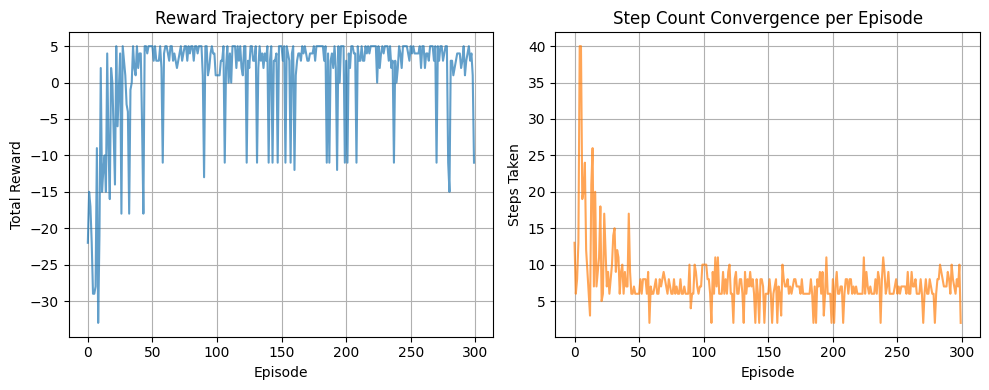

In [6]:
# Cell 7: Performance Metric Visualization (LOCKED)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(rewards_history, color='tab:blue', alpha=0.7)
plt.title("Reward Trajectory per Episode")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(steps_history, color='tab:orange', alpha=0.7)
plt.title("Step Count Convergence per Episode")
plt.xlabel("Episode")
plt.ylabel("Steps Taken")
plt.grid(True)

plt.tight_layout()
plt.show()
